# DSC - Machine Learning
**Date:** October 30, 2026
## Linear Regression: Predicting California House Prices

**Goal:** Build a simple model that predicts `median_house_value` from other information about a neighborhood.

**Libraries:** `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `joblib`, `kagglehub`

**Steps in this notebook**
1. Data loading
2. Data visualization
3. Data preprocessing (missing values)
4. Feature selection
5. Train/test split
6. Model training (Linear Regression)
7. Model evaluation (MAE, MSE, R-squared)
8. Save and load the model with joblib

## Step 0: Install and import libraries

In [2]:
%pip install kaggle hub pandas numpy matplotlib joblib scikit-learn

/Users/jeldy/Documents/LYHENG's DOC/AUPP/Sophomore/Fall - Sophomore 2026 /DSC - Fall/machine learning /.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import kagglehub
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 1: Data Loading

In [4]:
# Download the latest version of the dataset
path = kagglehub.dataset_download("camnugent/california-housing-prices")
print("Path to dataset files:", path)

# See which files are inside the folder
print(os.listdir(path))

Path to dataset files: /Users/jeldy/.cache/kagglehub/datasets/camnugent/california-housing-prices/versions/1
['housing.csv']


In [5]:
# Read the CSV file into a pandas DataFrame
csv_path = os.path.join(path, "housing.csv")

df = pd.read_csv(csv_path)

In [6]:
df.shape

(20640, 10)

In [7]:
df.head(10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
5,-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY
6,-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY
7,-122.25,37.84,52.0,3104.0,687.0,1157.0,647.0,3.1200,241400.0,NEAR BAY
8,-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,NEAR BAY
9,-122.25,37.84,52.0,3549.0,707.0,1551.0,714.0,3.6912,261100.0,NEAR BAY



**Guiding Questions**
1. How many rows and columns does the data have?
2. Which column do you think we want to predict? Why?

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


**Interpretation:** `info()` shows each column's name, data type, and how many values are *not* empty. If a column has fewer non-null values than the others, it has missing data. `ocean_proximity` is text (object), while the others are numbers.

**Guiding Questions**
1. Which column has fewer values than the rest?
2. Which column is text instead of numbers? Can Linear Regression use text directly?

In [9]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


**Interpretation:** This gives the count, average (mean), minimum, maximum, and quartiles of each number column. It helps us understand the typical size and range of each feature.

**Guiding Questions**
1. What is the average `median_house_value`?
2. Do the columns have very different ranges? (Compare `median_income` with `population`.)

## Step 2: Data Visualization

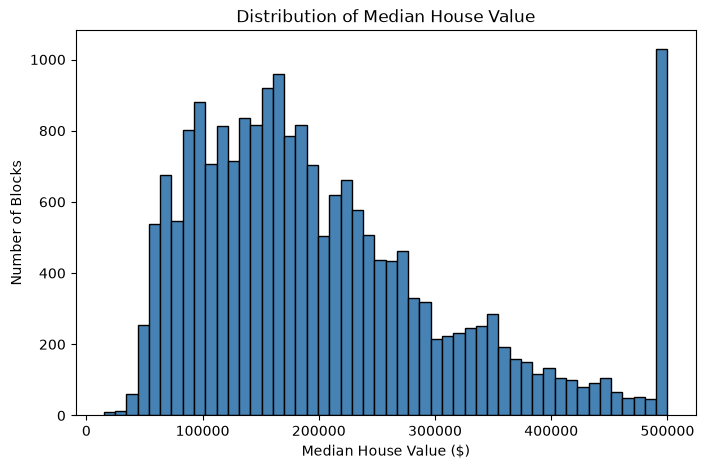

In [10]:
# Histogram of the median_house_value
plt.figure(figsize=(8, 5))
plt.hist(df["median_house_value"], bins=50, color="steelblue", edgecolor="black")
plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value ($)")
plt.ylabel("Number of Blocks")
plt.show()

**Interpretation:** A histogram shows how often each price range appears. Most houses are in the lower to middle price range. You may see a tall bar at the far right: prices above about $500,000 were *capped* (cut off) in this dataset.

**Guiding Questions**
1. Is the distribution balanced or skewed to one side?
2. What do you notice about the bar at the far right? What could cause it?

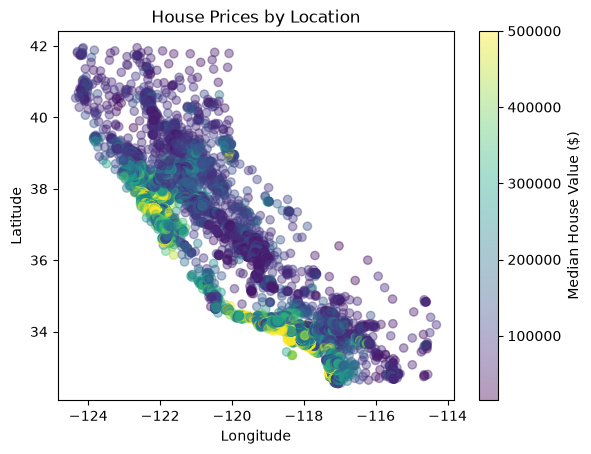

In [11]:
plt.scatter(
    df["longitude"],
    df["latitude"],
    c = df["median_house_value"],
    cmap = "viridis",
    alpha = 0.4
)

plt.colorbar(label = "Median House Value ($)")
plt.title("House Prices by Location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

**Interpretation:** Each dot is a neighborhood. The color shows the price, and the dot size shows the population. The shape looks like the California map. Expensive areas are mostly along the coast.

**Guiding Questions**
1. Where are the most expensive houses located?
2. Does location seem important for predicting price?

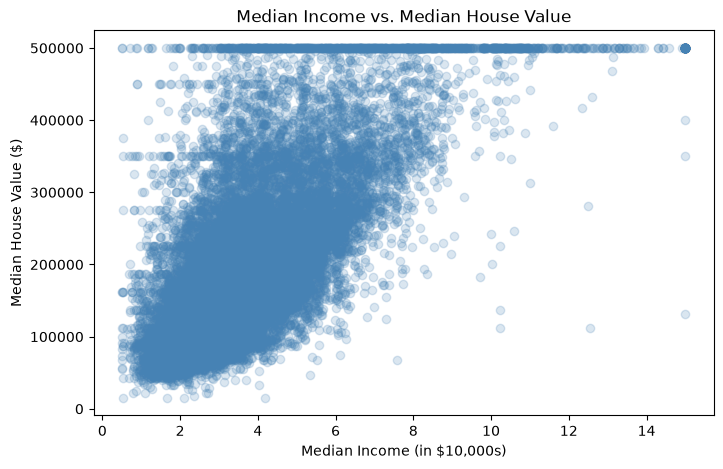

In [12]:
# Relationship between income and house value
plt.figure(figsize=(8, 5))
plt.scatter(df["median_income"], df["median_house_value"], alpha=0.2, color="steelblue")
plt.title("Median Income vs. Median House Value")
plt.xlabel("Median Income (in $10,000s)")
plt.ylabel("Median House Value ($)")
plt.show()

**Interpretation:** This scatter plot shows that when income goes up, house value usually goes up too. The dots form an upward trend, which is a good sign for Linear Regression (it finds straight-line relationships).

**Guiding Questions**
1. Is the relationship positive or negative?
2. Does the relationship look like a straight line? Where does it look different?

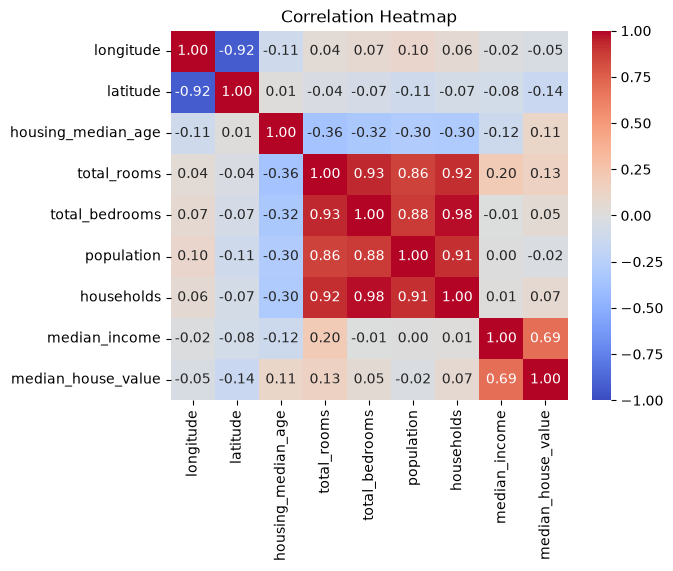

In [14]:
df = df.drop(columns = "ocean_proximity")
sns.heatmap(df.corr(), annot = True, fmt = ".2f", cmap = "coolwarm", vmin = -1, vmax = 1)
plt.title("Correlation Heatmap")
plt.show()

**Interpretation:** Correlation is a number from -1 to +1. Near +1 means "go up together", near -1 means "one goes up while the other goes down", near 0 means "no straight-line relationship". Look at the `median_house_value` row to see which features matter most.

**Guiding Questions**
1. Which feature has the highest correlation with `median_house_value`?
2. Which features are strongly correlated with each other (for example `total_rooms` and `households`)? Why might this happen?

## Step 3: Data Preprocessing (Missing Values and Imputing)

In [ ]:
# Count missing values in each column
missing = df.isnull().sum()

print(missing)

print("\nPercent missing in total_bedrooms: %.2f%%" % (missing["total_bedrooms"] / len(df) * 100))

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Percent missing in total_bedrooms: 1.00%


**Interpretation:** Machine learning models in scikit-learn cannot work with empty (NaN) values. Only `total_bedrooms` has missing values, and it is a small part of the data.

**Guiding Questions**
1. How many missing values are there, and in which column?
2. What are two ways to deal with missing values? (Hint: remove or fill.)

In [ ]:
# Fill the missing values with the median
median_value = df["total_bedrooms"].median()
df["total_bedrooms"] = df["total_bedrooms"].fillna(median_value)

print("Missing values left:", df["total_bedrooms"].isnull().sum())
print("Median used to fill:", median_value)

Missing values left: 0
Median used to fill: 435.0


**Interpretation:** We fills each empty cell with the **median** (the middle value) of the column. The median is a safe choice because it is not affected by very large or very small values. After this step, no empty values remain.

**Guiding Questions**
1. Why might the median be better than the mean here?
2. Imputing *before* splitting the data lets the test set "leak" into the training step. How could we avoid this? (Hint: fit the imputer on the training data only.)

## Step 4: Feature Selection

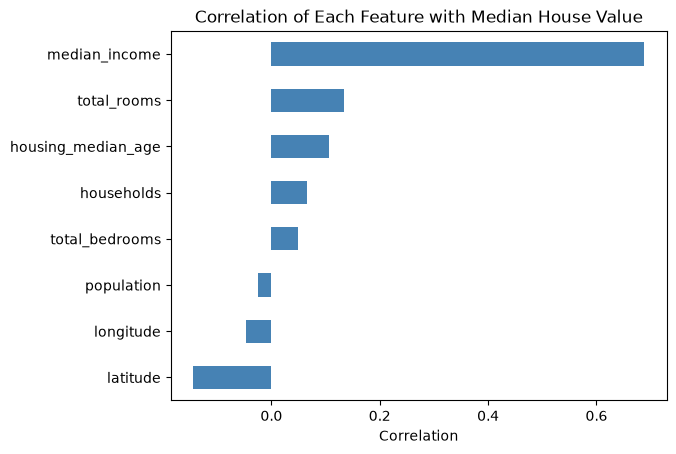

median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049457
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


In [ ]:
# Correlation of every numeric column with house price
corr = df.select_dtypes(include = "number").corr()
corr_with_target = corr["median_house_value"].drop("median_house_value")
corr_with_target = corr_with_target.sort_values()

corr_with_target.plot(kind = "barh", color = "steelblue")
plt.title("Correlation of Each Feature with Median House Value")
plt.xlabel("Correlation")
plt.show()

print(corr_with_target.sort_values(ascending = False))

**Interpretation:** This bar chart ranks features by how strongly they relate to house value. `median_income` is the strongest. Features with a value close to 0 give little straight-line information.

**Guiding Questions**
1. Which feature is the most useful? Which is the least?
2. Why is it good to remove features that do not help the model?

In [ ]:
# Choose features: keep numeric features with |correlation| >= 0.05
selected_features = corr_with_target[corr_with_target.abs() >= 0.05].index.tolist()
print("Selected features:", selected_features)

Selected features: ['latitude', 'households', 'housing_median_age', 'total_rooms', 'median_income']


In [ ]:

X = df[selected_features]   
y = df["median_house_value"]           

print("\nX shape:", X.shape)
print("y shape:", y.shape)


X shape: (20640, 5)
y shape: (20640,)


**Interpretation:** `X` holds the inputs (features) and `y` holds the answer we want to predict (target). We keep features that have at least a small relationship with price. We left out `ocean_proximity` because it is text, and keeping the notebook basic means using numbers only.

**Guiding Questions**
1. Which features were selected?
2. What could we do to use the text column `ocean_proximity` in a future version? (Hint: convert categories to numbers.)

## Step 5: Train/Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (16512, 5)
Testing set : (4128, 5)


**Interpretation:** We split the data into two parts: **80% for training** (the model learns from it) and **20% for testing** (we check the model on data it has never seen). `random_state=42` makes the split the same every time we run the code.

**Guiding Questions**
1. Why do we test the model on data it has not seen?
2. What would happen if we tested the model using the same data we trained on?

## Step 6: Model Training (Linear Regression)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained!")
print("Intercept:", round(model.intercept_, 2))

coef_df = pd.DataFrame({"Feature": selected_features, "Coefficient": model.coef_})
coef_df

Model trained!
Intercept: 84857.48


,Feature,Coefficient
0,latitude,-3682.322436
1,households,128.789779
2,housing_median_age,1887.489173
3,total_rooms,-17.948996
4,median_income,47074.100098


**Interpretation:** Linear Regression learns a formula: `price = intercept + (coef1 x feature1) + (coef2 x feature2) + ...`. Each **coefficient** tells us how much the price changes when that feature goes up by 1, while other features stay the same. A positive coefficient pushes the price up, a negative one pushes it down.

**Guiding Questions**
1. Which features have positive coefficients and which have negative ones?
2. Does the sign of each coefficient make sense to you? (For example, what does `median_income` do?)

## Step 7: Model Evaluation (MAE, MSE, R-squared)

In [ ]:
# Predict on both training and testing data
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

def evaluate(y_true, y_pred, stage):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    print(f"--- {stage} ---")
    print(f"MAE : {mae:,.2f}")
    print(f"MSE : {mse:,.2f}")
    print(f"RMSE: {np.sqrt(mse):,.2f}")
    print(f"R2  : {r2:.4f}\n")

evaluate(y_train, y_train_pred, "Training set")
evaluate(y_test, y_test_pred, "Testing set")

--- Training set ---
MAE : 58,047.98
MSE : 6,076,695,046.58
RMSE: 77,953.16
R2  : 0.5415

--- Testing set ---
MAE : 57,555.29
MSE : 6,211,969,412.86
RMSE: 78,816.05
R2  : 0.5419



**Interpretation:**
- **MAE** (Mean Absolute Error): the average size of the mistake, in dollars. Smaller is better.
- **MSE** (Mean Squared Error): the average of squared mistakes. It punishes big mistakes more. Smaller is better. (RMSE is its square root, back in dollars.)
- **R-squared**: how much of the price variation the model explains. 1.0 is perfect, 0 means no better than guessing the average.

If the train and test scores are close, the model is not overfitting.

**Guiding Questions**
1. On average, how many dollars is the model wrong by (MAE)?
2. What does your R-squared value mean in plain words? (Example: 0.60 means about 60% explained.)
3. Are the training and testing scores similar? What does that tell you?

In [ ]:
result_df = pd.DataFrame({"actual_value": y_test, "Predicted_value": y_test_pred})

result_df.head(10)

,actual_value,Predicted_value
8944,461100.0,189461.369531
12021,124600.0,215531.084593
7484,118100.0,162943.394613
16767,277000.0,252483.701041
5120,117400.0,244991.904610
1498,330200.0,345072.276882
6955,186900.0,297701.098016
17963,355200.0,283929.873248
6896,247600.0,226526.994917
7309,156700.0,163570.486304


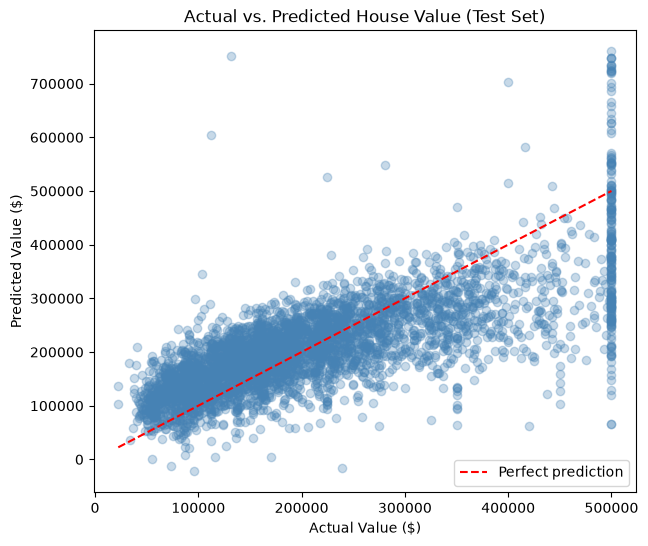

In [ ]:
# Actual vs. Predicted prices
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred, alpha=0.3, color="steelblue")
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")
plt.title("Actual vs. Predicted House Value (Test Set)")
plt.xlabel("Actual Value ($)")
plt.ylabel("Predicted Value ($)")
plt.legend()
plt.show()

**Interpretation:** If the model were perfect, every dot would sit on the red dashed line. Dots close to the line mean good predictions. Dots far away are big mistakes. Notice the flat row of dots at the top: these are the capped prices that the model cannot predict well.

**Guiding Questions**
1. Are most dots near the red line?
2. Does the model tend to guess too high or too low for expensive houses?

The model performance accuracy is bad simply because the outlier cluster influence that. What should we do here? Should we try cut that outlier out? Let's give a shot!

## Step 8: Save and Load the Model with joblib

In [ ]:
# Save the trained model to a file
joblib.dump(model, "linear_regression_housing.joblib")
print("Model saved! File size:", os.path.getsize("linear_regression_housing.joblib"), "bytes")

# Load it back
loaded_model = joblib.load("linear_regression_housing.joblib")
print("Model loaded!")


Model saved! File size: 1023 bytes
Model loaded!


**Interpretation:** Training can take time, so we save the trained model to a file with `joblib.dump`. Later we can load it with `joblib.load` and use it right away without training again. We check that the loaded model gives exactly the same predictions as the original.

**Guiding Questions**
1. Why is saving a model useful?
2. What file was created, and where is it on your computer?

In [ ]:
# Use the loaded model to predict a brand-new neighborhood
new_data = X_test.iloc[[0]]          # take one row as an example
print("Input features:")
print(new_data, "\n")

prediction = loaded_model.predict(new_data)
print(f"Predicted value : ${prediction[0]:,.0f}")
print(f"Actual value    : ${y_test.iloc[0]:,.0f}")

Input features:
      latitude  households  housing_median_age  total_rooms  median_income
8944     34.01       250.0                43.0       1160.0         2.9167 

Predicted value : $189,461
Actual value    : $461,100


**Interpretation:** This is how the saved model is used in real life: load it, give it new data with the same columns, and get a price prediction. Compare the predicted and actual values to see how close the model is for one example.

**Guiding Questions**
1. How close was the prediction to the actual value?
2. What would happen if the new data had different columns than the training data?

## Summary

| Step | What we did |
|------|-------------|
| Data loading | Downloaded the dataset with `kagglehub`, read it with `pandas` |
| Visualization | Histogram, map, scatter plot, correlation heatmap |
| Preprocessing | Filled missing `total_bedrooms` with the median |
| Feature selection | Kept numeric features correlated with price |
| Split | 80% train, 20% test |
| Training | `LinearRegression` |
| Evaluation | MAE, MSE (RMSE), R-squared |
| Saving | `joblib.dump` and `joblib.load` |

## Try it yourself
1. Change `test_size` to 0.3. How do the scores change?
2. Use only `median_income` as a feature. Is the model better or worse?
3. Convert `ocean_proximity` to numbers with `pd.get_dummies` and add it as a feature.
4. Fit the imputer on the training data only to avoid data leakage.
5. Use a more advanced model like random forest or gradient boosting. The steps are the same as before: create the model, `fit`, then `predict`.

   ```python
   from sklearn.ensemble import RandomForestRegressor
   from sklearn.metrics import r2_score

   rf_model = RandomForestRegressor(n_estimators = 100, random_state = 42)
   rf_model.fit(X_train, y_train)

   rf_pred = rf_model.predict(X_test)
   print("Random forest R-squared:", r2_score(y_test, rf_pred))
   ```

   Compare this R-squared with the one from `LinearRegression`. To try gradient boosting, swap in `from sklearn.ensemble import GradientBoostingRegressor` and `GradientBoostingRegressor(random_state = 42)`.
6. Try getting rid of the cutoff value (`df["median_house_value"].max()`) and see whether it really affects the performance of the model or not.

   ```python
   cutoff = df["median_house_value"].max()
   df_no_cap = df[df["median_house_value"] < cutoff]
   print("Rows before:", len(df), "| Rows after:", len(df_no_cap))
   ```

   Then repeat the split, training, and evaluation using `df_no_cap`.

## Limitation
Our linear regression model only reaches a modest R-squared. Here is why:

- **It can only draw straight lines.** Linear regression assumes that when a feature goes up, the price goes up (or down) at a steady rate. Real house prices are more complicated.
- **Location is not a straight line.** Latitude and longitude are used as plain numbers, but price does not rise steadily as you move north or east. Prices jump near the coast and in big cities like San Francisco and Los Angeles. A straight line cannot capture these "hot spots".
- **The price is capped.** Every house worth more than about $500,000 is recorded as exactly $500,001. The model never sees the true prices of expensive areas, so it cannot learn them.
- **Useful information was left out.** `ocean_proximity` is text, so we did not use it, even though it is closely tied to price.
- **Some features overlap.** `total_rooms`, `total_bedrooms`, `population`, and `households` move together, which makes the model's coefficients less reliable.
- **Outliers and skewed data.** A few very large values (for example, in `total_rooms` or `population`) pull the fitted line away from the typical data.
- **The data is noisy.** Each row is a whole neighborhood (block group), not a single house, so individual differences are averaged out.

Models that can handle curves and interactions, such as random forests, usually do much better on this dataset (see exercise 5).